# Data Cleaning & Preprocessing

In [ ]:
%pip install kagglehub pandas numpy matplotlib seaborn scikit-learn

Note: you may need to restart the kernel to use updated packages.


d:\Elevate Labs\.venv\Scripts\python.exe: No module named pip


d:\Elevate Labs\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 22.0k/22.0k [00:00<00:00, 244kB/s]

Extracting files...
Dataset downloaded to:
C:\Users\nemes\.cache\kagglehub\datasets\yasserh\titanic-dataset\versions\1

Files in dataset folder:
Titanic-Dataset.csv

FIRST 5 ROWS


   PassengerId  Survived  Pclass  \
0            1         0       3   
1            2         1       1   
2            3         1       3   
3            4         1       1   
4            5         0       3   

                                                Name     Sex   Age  SibSp  \
0                            Braund, Mr. Owen Harris    male  22.0      1   
1  Cumings, Mrs. John Bradley (Florence Briggs Th...  female  38.0      1   
2                             Heikkinen, Miss. Laina  female  26.0      0   
3       Futrelle, Mrs. Jacques Heath (Lily May Peel)  female  35.0      1   
4                           Allen, Mr. William Henry    male  35.0      0   

   Parch            Ticket     Fare Cabin Embarked  
0      0         A/5 21171   7.2500   NaN        S  
1      0          PC 17599  71.2833   C85        C  
2      0  STON/O2. 3101282   7.9250   NaN        S  
3      0            113803  53.1000  C123        S  
4      0            373450   8.0500   NaN        S  

D

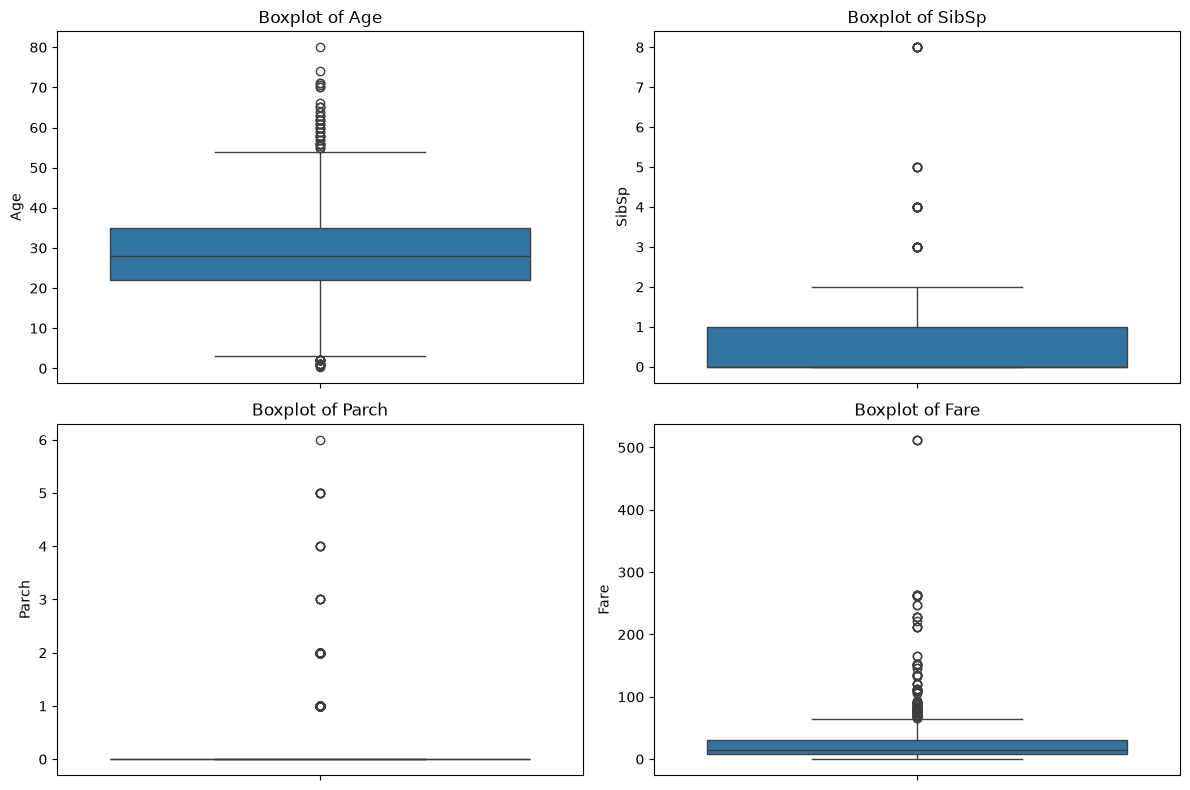


DATASET SIZE BEFORE OUTLIER REMOVAL
Rows: 891
Columns: 9

DATASET SIZE AFTER OUTLIER REMOVAL
Rows: 561
Columns: 9


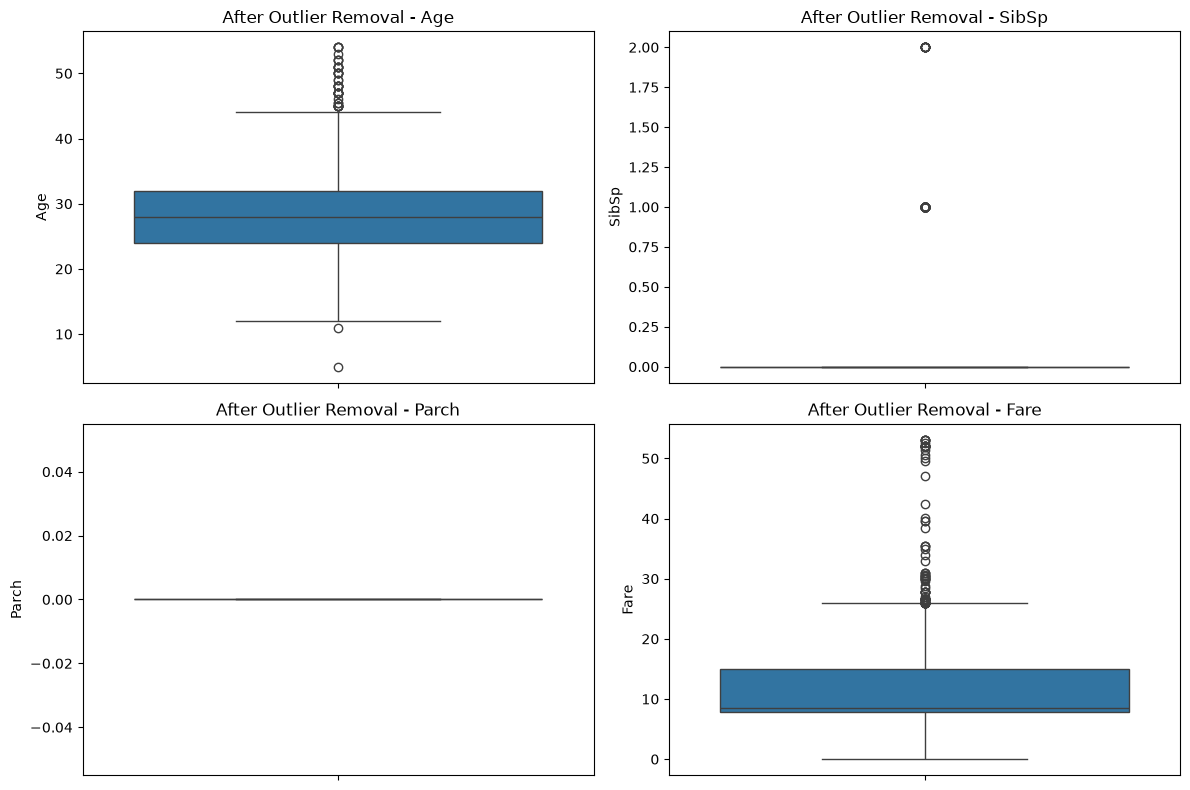


DATA AFTER STANDARDIZATION
   Survived  Pclass  Sex       Age     SibSp  Parch      Fare  Embarked_Q  \
0         0       3    0 -0.848100  1.839399    0.0 -0.613957           0   
2         1       3    1 -0.375036 -0.433515    0.0 -0.549982           0   
3         1       1    1  0.689358  1.839399    0.0  3.731563           0   
4         0       3    0  0.689358 -0.433515    0.0 -0.538135           0   
5         0       3    0 -0.138504 -0.433515    0.0 -0.499438           1   

   Embarked_S  
0           1  
2           1  
3           1  
4           1  
5           0  

FINAL DATASET SHAPE
(561, 9)

FINAL DATASET
    Survived  Pclass  Sex       Age     SibSp  Parch      Fare  Embarked_Q  \
0          0       3    0 -0.848100  1.839399    0.0 -0.613957           0   
2          1       3    1 -0.375036 -0.433515    0.0 -0.549982           0   
3          1       1    1  0.689358  1.839399    0.0  3.731563           0   
4          0       3    0  0.689358 -0.433515    0.0 -0.

In [2]:
import os
import kagglehub
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler

path = kagglehub.dataset_download("yasserh/titanic-dataset")

print("Dataset downloaded to:")
print(path)

files = os.listdir(path)

print("\nFiles in dataset folder:")
for file in files:
    print(file)

csv_file = None

for file in files:
    if file.endswith(".csv"):
        csv_file = os.path.join(path, file)
        break

if csv_file is None:
    raise FileNotFoundError("CSV file not found in Kaggle dataset.")

df = pd.read_csv(csv_file)

print("\n" + "=" * 60)
print("FIRST 5 ROWS")
print("=" * 60)

print(df.head())

print("\n" + "=" * 60)
print("DATASET SHAPE")
print("=" * 60)

print(df.shape)

print("\n" + "=" * 60)
print("DATASET INFORMATION")
print("=" * 60)

df.info()

print("\n" + "=" * 60)
print("DATA TYPES")
print("=" * 60)

print(df.dtypes)

print("\n" + "=" * 60)
print("STATISTICAL SUMMARY")
print("=" * 60)

print(df.describe())

print("\n" + "=" * 60)
print("MISSING VALUES BEFORE CLEANING")
print("=" * 60)

print(df.isnull().sum())

df["Age"] = df["Age"].fillna(df["Age"].median())

df["Embarked"] = df["Embarked"].fillna(
    df["Embarked"].mode()[0]
)

df.drop("Cabin", axis=1, inplace=True)

print("\n" + "=" * 60)
print("MISSING VALUES AFTER HANDLING")
print("=" * 60)

print(df.isnull().sum())

df["Sex"] = df["Sex"].map({
    "male": 0,
    "female": 1
})

df = pd.get_dummies(
    df,
    columns=["Embarked"],
    drop_first=True,
    dtype=int
)

print("\n" + "=" * 60)
print("DATA AFTER CATEGORICAL ENCODING")
print("=" * 60)

print(df.head())

df.drop(
    ["PassengerId", "Name", "Ticket"],
    axis=1,
    inplace=True
)

print("\n" + "=" * 60)
print("COLUMNS AFTER REMOVING UNNECESSARY FEATURES")
print("=" * 60)

print(df.columns.tolist())

numerical_columns = [
    "Age",
    "SibSp",
    "Parch",
    "Fare"
]

print("\nNumerical columns:")
print(numerical_columns)

plt.figure(figsize=(12, 8))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(y=df[column])

    plt.title(f"Boxplot of {column}")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

def remove_outliers_iqr(data, columns):

    data = data.copy()

    for column in columns:

        Q1 = data[column].quantile(0.25)

        Q3 = data[column].quantile(0.75)

        IQR = Q3 - Q1

        lower_bound = Q1 - 1.5 * IQR
        upper_bound = Q3 + 1.5 * IQR

        data = data[
            (data[column] >= lower_bound) &
            (data[column] <= upper_bound)
        ]

    return data

print("\n" + "=" * 60)
print("DATASET SIZE BEFORE OUTLIER REMOVAL")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

df = remove_outliers_iqr(
    df,
    numerical_columns
)

print("\n" + "=" * 60)
print("DATASET SIZE AFTER OUTLIER REMOVAL")
print("=" * 60)

print("Rows:", df.shape[0])
print("Columns:", df.shape[1])

plt.figure(figsize=(12, 8))

for i, column in enumerate(numerical_columns, 1):

    plt.subplot(2, 2, i)

    sns.boxplot(y=df[column])

    plt.title(f"After Outlier Removal - {column}")
    plt.ylabel(column)

plt.tight_layout()
plt.show()

scaler = StandardScaler()

df[numerical_columns] = scaler.fit_transform(
    df[numerical_columns]
)

print("\n" + "=" * 60)
print("DATA AFTER STANDARDIZATION")
print("=" * 60)

print(df.head())

print("\n" + "=" * 60)
print("FINAL DATASET SHAPE")
print("=" * 60)

print(df.shape)


print("\n" + "=" * 60)
print("FINAL DATASET")
print("=" * 60)

print(df.head(10))


print("\n" + "=" * 60)
print("FINAL MISSING VALUES")
print("=" * 60)

print(df.isnull().sum())


print("\n" + "=" * 60)
print("FINAL DATA TYPES")
print("=" * 60)

print(df.dtypes)

print("\n" + "=" * 60)
print("FINAL STATISTICAL SUMMARY")
print("=" * 60)

print(df.describe())

print("\nData Cleaning and Preprocessing Completed Successfully!")